# Mini Project: Do Oil Prices Affect Inflation?

**Question:** Do changes in the oil price affect US inflation? We look at three parts:

1. **How strong?** How much does inflation rise when oil gets 10% more expensive?
2. **How fast?** How many months does it take for the effect to show?
3. **Best model?** Can a neural network (GRU) predict inflation better than a regression?

**Data:** Monthly data from FRED (Federal Reserve Bank of St. Louis): the US consumer price index (series CPIAUCSL) and the WTI crude oil price (series MCOILWTICO), downloaded in November 2026. We use the period January 2000 to September 2026.

**Approach:** We turn both series into yearly % changes, find the time lag with the strongest link, fit two regression models (Model 1: simple, Model 2: multiple) and a GRU neural network (Model 3) on the years up to 2018, and compare their predictions on 2019–2026.

# Step 1: Importing Data

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.formula.api as smf

sns.set_theme(style="whitegrid")     # one clean look for all plots


In [3]:
# Run once: download the two series from FRED and save them as CSV files (done in November 2026).
# The lines are commented out so the saved data never changes, which keeps the results reproducible.
cpi = pd.read_csv("https://fred.stlouisfed.org/graph/fredgraph.csv?id=CPIAUCSL")     # CPI, all items
oil = pd.read_csv("https://fred.stlouisfed.org/graph/fredgraph.csv?id=MCOILWTICO")   # WTI oil price, $ per barrel
cpi.to_csv("cpi_fred.csv", index=False)
oil.to_csv("oil_fred.csv", index=False)

In [4]:
# Load the saved data
cpi = pd.read_csv("cpi_fred.csv")
oil = pd.read_csv("oil_fred.csv")

print(cpi.head())
print(oil.head())

  observation_date  CPIAUCSL
0       1947-01-01     21.48
1       1947-02-01     21.62
2       1947-03-01     22.00
3       1947-04-01     22.00
4       1947-05-01     21.95
  observation_date  MCOILWTICO
0       1986-01-01       22.93
1       1986-02-01       15.46
2       1986-03-01       12.61
3       1986-04-01       12.84
4       1986-05-01       15.38


In [5]:
# Convert the dates from text to real dates, so pandas can work with time
cpi["observation_date"] = pd.to_datetime(cpi["observation_date"])
oil["observation_date"] = pd.to_datetime(oil["observation_date"])

# Merge the data and fill the missing value

In [6]:
# Merge the two series by month.
# pd.merge keeps only months found in both tables (an inner join),
# so the data starts in January 1986, when the oil series begins.

data = pd.merge(cpi, oil, on="observation_date")
# Short column names, and the date as the row index

data = data.rename(columns={"observation_date": "date",
                            "CPIAUCSL": "cpi",
                            "MCOILWTICO": "oil"
                            })
data = data.set_index("date")

In [7]:
print(data.head())
print(data.tail())
print(data.shape)
print(data.isna().sum())

              cpi    oil
date                    
1986-01-01  109.9  22.93
1986-02-01  109.7  15.46
1986-03-01  109.1  12.61
1986-04-01  108.7  12.84
1986-05-01  109.0  15.38
                cpi     oil
date                       
2026-06-01  332.568   84.81
2026-07-01  332.813   80.46
2026-08-01  334.131   83.90
2026-09-01  336.298   97.31
2026-10-01  337.476  102.07
(490, 2)
cpi    1
oil    0
dtype: int64


In [8]:
# Show every month with a missing value in any column
print(data[data.isna().any(axis=1)])

            cpi    oil
date                  
2025-10-01  NaN  60.89


In [9]:
# Fill the gaps by linear interpolation: the average of the month before and the month after
data["cpi"] = data["cpi"].interpolate()
print(data.isna().sum())     # should now be 0 for both columns

cpi    0
oil    0
dtype: int64


In [10]:
# Check: October should be exactly halfway between September and November
print(data.loc["2025-09-01":"2025-11-01", ["cpi"]])

                cpi
date               
2025-09-01  324.245
2025-10-01  324.654
2025-11-01  325.063


The CPI for October 2025 is missing in the FRED data: it was never published because of the US government shutdown in autumn 2025. We filled it by linear interpolation, the average of September and November: CPI 324.654 (from 324.245 and 325.063).

The value is missing completely at random (MCAR): the gap was caused by the shutdown, not by the price level. With only one missing month in a slowly changing series, linear interpolation gives a reliable estimate. Deleting the month instead would break the monthly sequence that the yearly % changes rely on.

# Step 2: Yearly % changes

In [11]:
# Yearly % change: each month compared with the same month one year earlier.

# .pct_change(12) compares with 12 rows (months) earlier, and * 100 turns it into percent.

# Example: CPI 100 in January 2023 and 103 in January 2024 gives inflation (103 − 100) / 100 × 100 = 3%.

data["inflation"] = data["cpi"].pct_change(12) * 100              # Inflation
data["oil_change"] = data["oil"].pct_change(12) * 100             # yearly oil price change

In [12]:
# Keep January 2000 to September 2026.
# January 2000 still gets its value from January 1999.
# The end date is fixed, so new monthly data on FRED does not change the results.
data = data.loc["2000-01-01":"2026-09-01"]
print(data.head())
print(data.tail())
print(data.shape)

              cpi    oil  inflation  oil_change
date                                           
2000-01-01  169.3  27.26   2.792957  117.731629
2000-02-01  170.0  29.37   3.217972  144.546211
2000-03-01  171.0  29.84   3.762136  103.269755
2000-04-01  170.9  25.72   3.013864   48.584633
2000-05-01  171.2  28.79   3.132530   62.471783
                cpi     oil  inflation  oil_change
date                                              
2026-05-01  333.979  102.13   4.166615   64.275374
2026-06-01  332.568   84.81   3.463531   24.409564
2026-07-01  332.813   80.46   3.303856   17.648779
2026-08-01  334.131   83.90   3.353016   29.355535
2026-09-01  336.298   97.31   3.717251   52.141964
(321, 4)


Why use the change, not the price itself?

Two reasons:

1. It matches inflation. Inflation is itself a yearly % change (of the CPI).
Comparing a % change with a % change is like comparing like with like: “when oil rises 25% over a year, how much do consumer prices rise?”
2. It avoids spurious correlation. Raw prices (oil and CPI) both drift upward over decades.
Two series that both trend upward always look correlated, even when one doesn’t affect the other. Using changes removes that shared trend.

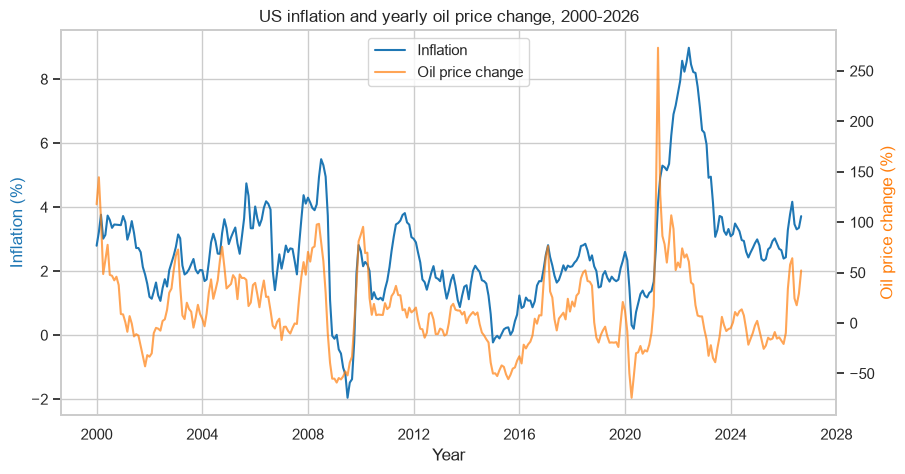

In [13]:
# Inflation (left axis) and the yearly oil price change (right axis), 2000–2026
fig, ax1 = plt.subplots(figsize=(10, 5))

sns.lineplot(data=data, x="date", y="inflation", ax=ax1, color="tab:blue", label="Inflation", legend=False)
ax1.set_ylabel("Inflation (%)", color="tab:blue")
ax1.set_xlabel("Year")

ax2 = ax1.twinx()                    # a second y-axis sharing the same x-axis
sns.lineplot(data=data, x="date", y="oil_change", ax=ax2, color="tab:orange", alpha=0.7,
             label="Oil price change", legend=False)
ax2.set_ylabel("Oil price change (%)", color="tab:orange")
ax2.grid(False)                      # keep only one set of grid lines

# One legend for the lines on both axes
lines = ax1.get_lines() + ax2.get_lines()
ax1.legend(lines, [line.get_label() for line in lines], loc="upper center")

plt.title("US inflation and yearly oil price change, 2000-2026")
plt.show()

**What the plot shows:** inflation (blue) and the yearly oil price change (orange) move together in the big episodes. In 2008–2009, oil fell by more than 50% and inflation turned negative. In 2014–2015, oil roughly halved and inflation fell to about 0. In 2020, Covid crashed the oil price. And in 2021, oil was up about 270%, a base effect because oil had been extremely cheap a year earlier, followed by the inflation peak of 9% in 2022.

Note the different scales: the oil change moves between about −75% and +270%, inflation only between −2% and 9%. Inflation also seems to follow oil with a short delay, so in Step 3 we measure the timing.

# Step 3: Finding the best lag

In [17]:
# For each lag k (0 to 18 months): how strongly is inflation correlated with the oil change k months earlier?
# We use only the training years 2000-2018, so the test years 2019-2026 play no part in choosing the lags
train_years = data.loc[:"2018-12-01"]

lags = []
correlations = []

for k in range(0, 13):
    oil_k = train_years["oil_change"].shift(k)              # oil change k months earlier
    lags.append(k)
    correlations.append(train_years["inflation"].corr(oil_k))

lag_fr = pd.DataFrame({"lag_months": lags, "correlation": correlations})
print(lag_fr.round(3))

    lag_months  correlation
0            0        0.727
1            1        0.771
2            2        0.734
3            3        0.674
4            4        0.608
5            5        0.541
6            6        0.473
7            7        0.403
8            8        0.322
9            9        0.249
10          10        0.191
11          11        0.140
12          12        0.068


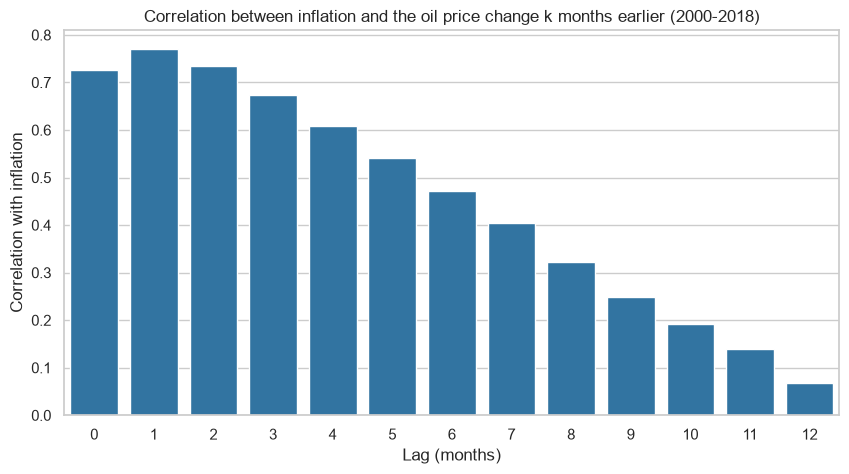

In [18]:
plt.figure(figsize=(10, 5))
sns.barplot(data=lag_fr, x="lag_months", y="correlation", color="tab:blue")
plt.xlabel("Lag (months)")
plt.ylabel("Correlation with inflation")
plt.title("Correlation between inflation and the oil price change k months earlier (2000-2018)")
plt.show()

In [19]:
# the lag with the highest correlation
best = lag_fr.loc[lag_fr["correlation"].idxmax()]
print("Best lag:", int(best["lag_months"]), "month(s), correlation", round(best["correlation"], 3))

Best lag: 1 month(s), correlation 0.771


We compute these correlations on the training years 2000–2018 only, so the test years 2019–2026 do not influence which lags we choose.

The correlation is highest at a lag of 1 month (0.77), slightly higher than in the same month (0.73). So this month’s inflation is most closely related to the oil price change one month earlier. That fits the economics: the CPI contains petrol, which reacts to oil almost immediately.

After that, the link fades over the year: the correlation is 0.47 after 6 months and close to zero (0.07) after 12 months. So the effect starts fast but is spread out over about a year, which is why Model 1 uses a lag of 1 month and Model 2 uses lags up to 12 months.

Our models use lags 1–12: Model 1 uses lag 1, Model 2 uses lags 1, 3, 6 and 12, and the GRU reads all 12 months. Lag 0 (the same month) is not used, because a model may only use information from earlier months. Lags 13–18 are only shown to check that the link stays weak after a year (at most 0.11), so there is no reason to go beyond 12 months.

# Step 4: Model 1, Simple Linear Regression

In [20]:
# the oil change from one month earlier
data["oil_lag1"] = data["oil_change"].shift(1)

# drop rows with missing values (only January 2000, which has no oil change from the month before)
model_data = data.dropna()

# split by time: train on 2000-2018, test on 2019-2026
train = model_data.loc[:"2018-12-01"]
test = model_data.loc["2019-01-01":]

# fit Model 1 on the training data
# HAC (Newey-West) standard errors: they correct the p-values for autocorrelated errors.
# maxlags=12, because the yearly change of one month shares 11 of its 12 months with the next month's
model1 = smf.ols("inflation ~ oil_lag1", data=train).fit(cov_type="HAC", cov_kwds={"maxlags": 12})
print(model1.summary())

# evaluate on the test period
pred1 = model1.predict(test)
rmse1 = np.sqrt(np.mean((test["inflation"] - pred1) ** 2))
print("Test RMSE, Model 1:", rmse1)

                            OLS Regression Results                            
Dep. Variable:              inflation   R-squared:                       0.595
Model:                            OLS   Adj. R-squared:                  0.593
Method:                 Least Squares   F-statistic:                     45.88
Date:                Fri, 13 Nov 2026   Prob (F-statistic):           1.09e-10
Time:                        17:47:15   Log-Likelihood:                -273.34
No. Observations:                 227   AIC:                             550.7
Df Residuals:                     225   BIC:                             557.5
Df Model:                           1                                         
Covariance Type:                  HAC                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept      1.8367      0.151     12.146      0.0

We used oil_lag1 (last month’s oil change) instead of oil_change (this month’s) for three reasons:

1. The data told us to. In the lag plot, the correlation with inflation was highest at lag 1 (0.77), slightly higher than lag 0 (0.73). So last month’s oil change explains inflation best.

2. Cause comes before effect. Oil prices affect consumer prices through petrol, transport and production, which takes some time. Using the earlier month matches that order: first oil changes, then prices follow.

3. It makes the model useful for prediction. To predict this month’s inflation, we can only use information we already have. Last month’s oil change is known; this month’s isn’t fully known yet. A model using oil_lag1 can actually forecast.

Result: in 2000–2018, oil price changes explain about 60% of the variation in inflation (R² = 0.595). A 10% oil price rise goes with about 0.27 percentage points higher inflation the next month (slope 0.0271), and with an unchanged oil price, inflation is about 1.8% (the intercept).

The errors are strongly autocorrelated (Durbin–Watson 0.26; no autocorrelation would give about 2). This is expected, because the yearly change of one month shares 11 of its 12 months with the next month’s. Ordinary p-values would then be too optimistic, so we use HAC (Newey–West) standard errors, which correct for this. The slope stays clearly significant (p < 0.001). HAC changes only the standard errors and p-values, not the slope or the predictions. On the test years 2019–2026, the typical prediction error is 2.29 percentage points.

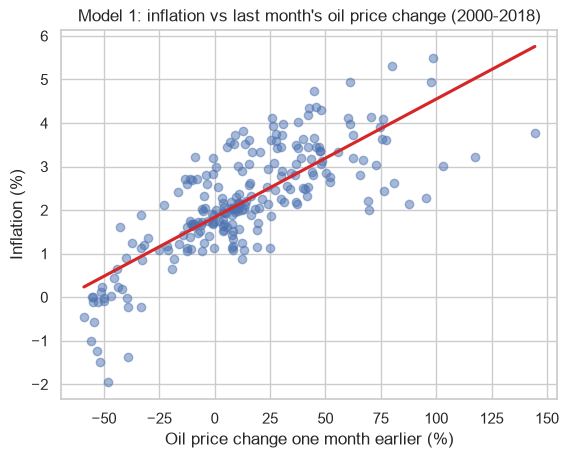

In [21]:
# Model 1 as a picture: each dot is one training month, the line is the fitted regression
# sns.regplot draws the points and the same least-squares line as Model 1
sns.regplot(data=train, x="oil_lag1", y="inflation", ci=None,
            scatter_kws={"alpha": 0.5}, line_kws={"color": "tab:red"})
plt.xlabel("Oil price change one month earlier (%)")
plt.ylabel("Inflation (%)")
plt.title("Model 1: inflation vs last month's oil price change (2000-2018)")
plt.show()

**What the plot shows:** the points follow the red line, so the link is clear. But at both ends the points tend to lie below the line: after very large oil rises (for example +145% in March 2000), inflation rose less than the line predicts, and after large falls (2009, 2015), inflation fell more. So the relationship is slightly curved, which a straight line cannot capture. Part of the bend comes from the % scale itself: oil can rise by +270% but fall by at most −100%, so big rises get large numbers. The GRU in Step 6 can learn curved effects like this.

# Step 5: Model 2, Multiple Linear Regression

Model 2 adds earlier oil price changes, to capture the slow tail we saw in Step 3: lags of 1, 3, 6 and 12 months, a simple spread over one year.

The 12-month lag needs data from 12 months earlier, so the year 2000 drops out. To keep the comparison fair, Model 1 is fitted again on exactly the same months as Model 2 (training: January 2001 – December 2018, 216 months; test: January 2019 – September 2026, 93 months). That is why Model 1’s adjusted R² changes slightly, from 0.593 to 0.607: it is the same model, fitted without the year 2000.

In [ ]:
# create all the lags we need
for k in [1, 3, 6, 12]:
    data[f"oil_lag{k}"] = data["oil_change"].shift(k)

# same rows for all models
model_data = data.dropna()
train = model_data.loc[:"2018-12-01"]
test = model_data.loc["2019-01-01":]

# Model 1 again, on the same rows (so the comparison is fair)
model1 = smf.ols("inflation ~ oil_lag1", data=train).fit(cov_type="HAC", cov_kwds={"maxlags": 12})
pred1 = model1.predict(test)
rmse1 = np.sqrt(np.mean((test["inflation"] - pred1) ** 2))
print("Adj. R², Model 1:", round(model1.rsquared_adj, 3))

# Model 2: several lags (HAC standard errors, as in Model 1)
model2 = smf.ols("inflation ~ oil_lag1 + oil_lag3 + oil_lag6 + oil_lag12", data=train).fit(cov_type="HAC", cov_kwds={"maxlags": 12})
print(model2.summary())

pred2 = model2.predict(test)
rmse2 = np.sqrt(np.mean((test["inflation"] - pred2) ** 2))
print("Test RMSE, Model 2:", rmse2)

Adj. R², Model 1: 0.607
                            OLS Regression Results                            
Dep. Variable:              inflation   R-squared:                       0.664
Model:                            OLS   Adj. R-squared:                  0.658
Method:                 Least Squares   F-statistic:                     26.80
Date:                Fri, 13 Nov 2026   Prob (F-statistic):           5.52e-18
Time:                        17:50:36   Log-Likelihood:                -239.60
No. Observations:                 216   AIC:                             489.2
Df Residuals:                     211   BIC:                             506.1
Df Model:                           4                                         
Covariance Type:                  HAC                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept      1.7164      0

In [25]:
# Do the delayed lags (3, 6 and 12 months) matter together? H0: all three slopes are 0 (uses the HAC errors)
print(model2.wald_test("oil_lag3 = 0, oil_lag6 = 0, oil_lag12 = 0", scalar=True))

# Total effect over a year: the sum of the four slopes, with its 95% confidence interval
print(model2.t_test("oil_lag1 + oil_lag3 + oil_lag6 + oil_lag12 = 0"))

<Wald test (chi2): statistic=10.363124131847325, p-value=0.015718740361680243, df_denom=3>
                             Test for Constraints                             
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
c0             0.0395      0.004      9.758      0.000       0.032       0.047


Result: Model 2 explains about 66% of the variation in inflation in the training years (adjusted R² = 0.658, compared with 0.607 for Model 1 on the same months). Lag 1 (0.0295) is clearly significant (p < 0.001). The later lags are smaller and not significant one by one: lag 12 (0.0062) is borderline (p = 0.10), lag 6 (0.0043) is not significant (p = 0.28), and lag 3 is about zero. But together they matter: the joint test rejects that the slopes of lags 3, 6 and 12 are all zero (p = 0.016).

The sum of the four slopes is 0.0395 (95% confidence interval 0.032 to 0.047): a lasting 10% oil price rise goes with about 0.4 percentage points higher inflation over a year, compared with 0.27 one month later in Model 1. So oil affects inflation mainly quickly, with a smaller delayed part.

As in Model 1, the errors are autocorrelated (Durbin–Watson 0.35), so all p-values use HAC standard errors. The residuals are also slightly skewed (Omnibus p = 0.046), which matters little with 216 observations.

In [26]:
# VIF (variance inflation factor): how much each lag overlaps with the other lags in Model 2
# VIF = 1 means no overlap; values above 5 are a common warning sign
from statsmodels.stats.outliers_influence import variance_inflation_factor

X_vif = model2.model.exog              # Model 2's training data (the first column is the intercept)
names = model2.model.exog_names

vif = pd.DataFrame({"variable": names[1:],
                    "VIF": [variance_inflation_factor(X_vif, i) for i in range(1, len(names))]})
print(vif.round(2))

    variable   VIF
0   oil_lag1  3.09
1   oil_lag3  4.48
2   oil_lag6  2.17
3  oil_lag12  1.22


**Is lag 3 a problem?** Lag 3 is close to zero because it overlaps with lags 1 and 6 and adds little new information. The yearly oil change measured 3 months ago shares 10 of its 12 months with the one measured 1 month ago, so the two move closely together. The VIF check above measures this overlap: all values are below 5 (the highest is 4.5, for lag 3), so the overlap is moderate and not a problem for the model. We therefore keep lag 3. If the overlap were stronger, ridge regression (a regression that shrinks overlapping slopes towards zero) would be an option.

On the test years 2019–2026, Model 2’s typical prediction error (test RMSE) is 2.09.

# Step 6: Model 3, a Recurrent Neural Network (GRU)

The regression models use fixed lags (1, 3, 6 and 12 months) and straight-line effects. A recurrent neural network (RNN) works differently: it reads the past months one by one, in order, and keeps a “memory” that it updates after each month. At the end, it turns that memory into a prediction. A GRU (Gated Recurrent Unit) is a common type of RNN: its gates decide at each month how much of the old memory to keep and how much of the new month to take in. So the GRU can learn by itself which months matter and how, including curved effects.

Setup:

- **Input:** for each month, the oil price changes of the 12 months before it, as a sequence. **Target:** that month’s inflation. Like the other models, the GRU only gets oil information.
- **Same months:** trained on 2001–2018 (216 months) and tested on 2019–2026 (93 months).
- **Scaling:** inputs and target are scaled to around 0 with the training mean and standard deviation, because neural networks learn better with small numbers.
- **Choosing the size:** the number of memory units decides how many weights the network has (2 units: 33 weights, 8 units: 273, 16 units: about 930). More weights can learn more, but can also overfit more. We choose the size with time-series cross-validation inside the training years: three folds, each training on the years before a 3-year validation period (2010–2012, 2013–2015 and 2016–2018) and measuring the error there. The size with the lowest average error is chosen. The test years are not used for this.
- **Final model:** the chosen size is trained on all training years and tested once on 2019–2026. Because the result depends on the random start, we train it from 5 different starts and average the 5 predictions. The other settings (300 training rounds, learning rate 0.01) were fixed beforehand.

In [27]:
import torch
import torch.nn as nn

# Model 3: a GRU, a recurrent neural network
# Input for each month: the oil price changes of the 12 months before it, as a sequence (oldest month first)
# Target: inflation in that month
window = 12

X, y, dates = [], [], []
for t in range(window, len(data)):
    X.append(data["oil_change"].iloc[t - window:t].values)   # months t-12, ..., t-1
    y.append(data["inflation"].iloc[t])                       # month t
    dates.append(data.index[t])

X = np.array(X)                  # one row per month, 12 columns
y = np.array(y)
dates = pd.DatetimeIndex(dates)

# same training and test months as the other models
is_train = dates <= "2018-12-01"
is_test = dates >= "2019-01-01"
X_train, y_train = X[is_train], y[is_train]
X_test, y_test = X[is_test], y[is_test]
print(X_train.shape, X_test.shape)    # (216, 12) and (93, 12)

# scale the numbers to around 0, using the training data only (neural networks learn better this way)
x_mean, x_std = X_train.mean(), X_train.std()
y_mean, y_std = y_train.mean(), y_train.std()

# PyTorch wants tensors with the shape (months, 12 steps, 1 value per step)
X_train_t = torch.tensor((X_train - x_mean) / x_std, dtype=torch.float32).unsqueeze(-1)
X_test_t = torch.tensor((X_test - x_mean) / x_std, dtype=torch.float32).unsqueeze(-1)
y_train_t = torch.tensor((y_train - y_mean) / y_std, dtype=torch.float32).unsqueeze(-1)

(216, 12) (93, 12)


In [28]:
# the GRU reads the 12 months one by one and updates its memory after each month;
# a linear layer then turns the final memory into one prediction
class GRUModel(nn.Module):
    def __init__(self, hidden_size):
        super().__init__()
        self.gru = nn.GRU(input_size=1, hidden_size=hidden_size, batch_first=True)
        self.out = nn.Linear(hidden_size, 1)

    def forward(self, x):
        _, memory = self.gru(x)        # the memory after the last month
        return self.out(memory[-1])


def train_gru(X_t, y_t, hidden_size, seed):
    torch.manual_seed(seed)            # fixes the random starting weights, so the result can be repeated
    model = GRUModel(hidden_size)
    optimizer = torch.optim.Adam(model.parameters(), lr=0.01)
    loss_fn = nn.MSELoss()
    for epoch in range(300):                       # 300 rounds over the data
        optimizer.zero_grad()
        loss = loss_fn(model(X_t), y_t)            # how wrong the model is now
        loss.backward()                            # in which direction to change each weight
        optimizer.step()                           # change the weights a little
    return model


def predict(model, X_t):
    with torch.no_grad():
        return model(X_t).squeeze().numpy() * y_std + y_mean   # back to inflation in %

In [29]:
# choose the size with time-series cross-validation: three folds, each trains on the years
# before a 3-year validation period and measures the error on that period
# (the test years 2019-2026 are not used here)
folds = [(108, 144),    # train 2001-2009, validate 2010-2012
         (144, 180),    # train 2001-2012, validate 2013-2015
         (180, 216)]    # train 2001-2015, validate 2016-2018

sizes = [2, 4, 8, 16]
cv_rmse = []
for size in sizes:
    rmses = []
    for start, end in folds:
        for seed in range(5):
            m = train_gru(X_train_t[:start], y_train_t[:start], size, seed)
            rmses.append(np.sqrt(np.mean((y_train[start:end] - predict(m, X_train_t[start:end])) ** 2)))
    cv_rmse.append(np.mean(rmses))      # average over 3 folds x 5 random starts

cv_table = pd.DataFrame({"memory_units": sizes, "cv_RMSE": cv_rmse})
print(cv_table.round(3))

best_size = int(cv_table.loc[cv_table["cv_RMSE"].idxmin(), "memory_units"])
print("Chosen size:", best_size)

   memory_units  cv_RMSE
0             2    0.829
1             4    0.828
2             8    0.939
3            16    0.973
Chosen size: 4


In [30]:
# Model 3: the chosen size, trained on all training years (2001-2018) and tested once on 2019-2026
# we train it from 5 random starts and average the 5 predictions, so the result does not depend on luck
fits, preds = [], []
for seed in range(5):
    m = train_gru(X_train_t, y_train_t, best_size, seed)
    fits.append(predict(m, X_train_t))
    preds.append(predict(m, X_test_t))
    print("seed", seed, "test RMSE:", round(np.sqrt(np.mean((y_test - preds[-1]) ** 2)), 3))

fit3 = np.mean(fits, axis=0)       # average of the 5 networks
pred3 = np.mean(preds, axis=0)

r2_train3 = 1 - np.sum((y_train - fit3) ** 2) / np.sum((y_train - y_train.mean()) ** 2)
rmse3 = np.sqrt(np.mean((y_test - pred3) ** 2))
pred3 = pd.Series(pred3, index=dates[is_test])     # with dates, for the plot in Step 7

print("Weights per network:", sum(p.numel() for p in m.parameters()))
print("R² on the training years, Model 3:", round(r2_train3, 3))
print("Test RMSE, Model 3 (GRU, average of 5):", rmse3)

seed 0 test RMSE: 1.978
seed 1 test RMSE: 1.888
seed 2 test RMSE: 1.894
seed 3 test RMSE: 2.121
seed 4 test RMSE: 2.078
Weights per network: 89
R² on the training years, Model 3: 0.844
Test RMSE, Model 3 (GRU, average of 5): 1.9808811511629998


**Choosing the size:** in the time-series cross-validation, the small networks did best (average validation RMSE 0.83 for both 2 and 4 memory units, compared with 0.94 for 8 and 0.97 for 16). Bigger networks learn the training years too closely, so they predict new years worse: overfitting. The cross-validation chose 4 memory units (89 weights per network).

**Result:** Model 3’s test RMSE is 1.98 (the average of the 5 networks). Its R² on the training years is high (0.84), but this is not a fair comparison with the regressions: a flexible network can fit the data it learned from very closely. The fair measure is the test RMSE, on years the network has never seen. Step 7 compares it with the other models.

But this number is uncertain: the single networks vary with the random start (test RMSE from 1.89 to 2.12), and the test period is short and dominated by one unusual episode (2021–2023). And unlike the regression, the GRU is a black box: it cannot tell us how large the oil effect is or after how many months it comes.

# Step 7: Final comparison

**Baseline:** the simplest possible model ignores oil and always predicts the average inflation of the training years. Like a weather forecast that must beat “the usual temperature for this time of year”, every model has to beat this baseline to be useful.

In [31]:
# Baseline: ignore oil and always predict the average inflation of the training years
baseline = train["inflation"].mean()
rmse0 = np.sqrt(np.mean((test["inflation"] - baseline) ** 2))
print("Baseline (training mean):", round(baseline, 2))
print("Test RMSE, baseline:", rmse0)

Baseline (training mean): 2.13
Test RMSE, baseline: 2.635260122580731


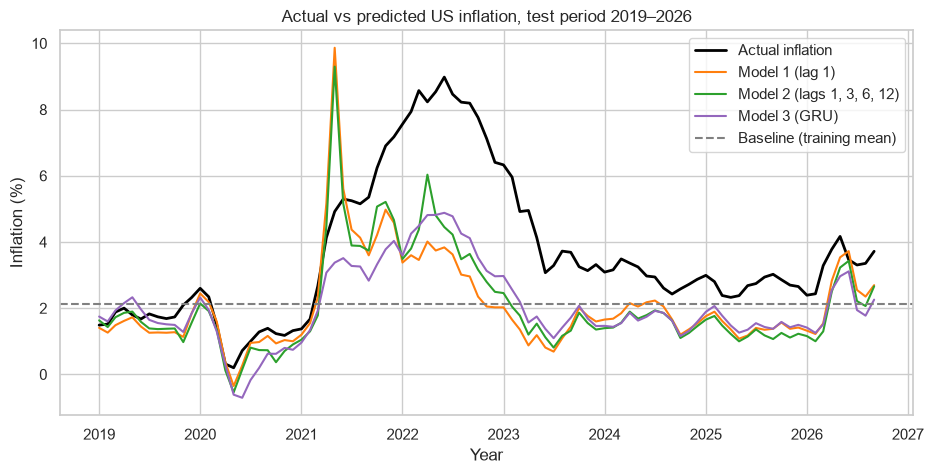

In [32]:
plt.figure(figsize=(11, 5))
sns.lineplot(x=test.index, y=test["inflation"], label="Actual inflation", color="black", linewidth=2)
sns.lineplot(x=test.index, y=pred1, label="Model 1 (lag 1)", color="tab:orange")
sns.lineplot(x=test.index, y=pred2, label="Model 2 (lags 1, 3, 6, 12)", color="tab:green")
sns.lineplot(x=pred3.index, y=pred3, label="Model 3 (GRU)", color="tab:purple")
plt.axhline(baseline, label="Baseline (training mean)", color="gray", linestyle="--")

plt.ylabel("Inflation (%)")
plt.xlabel("Year")
plt.title("Actual vs predicted US inflation, test period 2019–2026")
plt.legend()
plt.show()

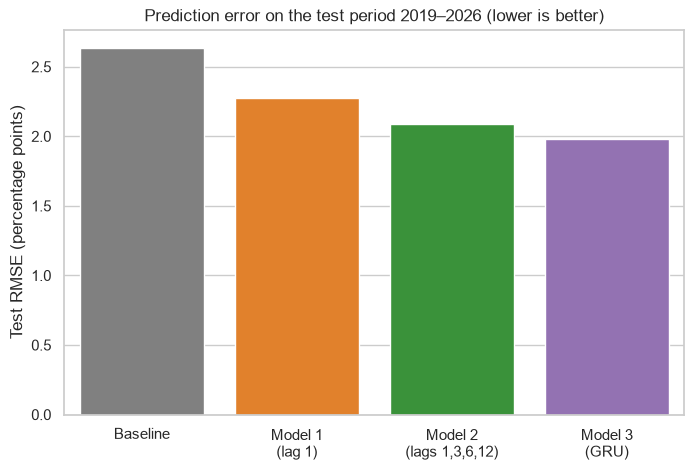

In [33]:
results = pd.DataFrame({
    "model": ["Baseline", "Model 1\n(lag 1)", "Model 2\n(lags 1,3,6,12)", "Model 3\n(GRU)"],
    "rmse": [rmse0, rmse1, rmse2, rmse3]
})

plt.figure(figsize=(8, 5))
sns.barplot(data=results, x="model", y="rmse", hue="model", legend=False,
            palette=["gray", "tab:orange", "tab:green", "tab:purple"])
plt.xlabel("")
plt.ylabel("Test RMSE (percentage points)")
plt.title("Prediction error on the test period 2019–2026 (lower is better)")
plt.show()

Three things to notice in this plot:

- **All models miss most of the 2021–2023 surge.** At the 9% peak in mid-2022 they predict only about 3.5–5%, and from mid-2023 they mostly predict 1–2% while actual inflation stays near 3%. Oil alone cannot explain this period.
- **The GRU does not overreact to the 2021 oil spike.** In spring 2021 the oil price was about 270% higher than a year earlier, because it had collapsed in 2020. The regressions turn this into a sudden jump in predicted inflation (almost 10% for Model 1), while the GRU stays at about 3.5%. In 2022 it then stays high for longer (around 4.5–5%), probably because it looks at the whole past year of oil changes. Most of its advantage comes from these two periods. On the other hand, it recovers more slowly after the 2020 dip.
- **Model 2’s second bump in early 2022 (about 6%).** This is the 12-month lag repeating the spring 2021 oil spike one year later. It happened to land near the real inflation peak, which is part of why Model 2 is the best regression, so part of its advantage may be lucky timing.

In [34]:
summary = pd.DataFrame({
    "model": ["Baseline", "Model 1 (lag 1)", "Model 2 (lags 1,3,6,12)", "Model 3 (GRU)"],
    "R2_train": [0, model1.rsquared, model2.rsquared, r2_train3],
    "test_RMSE": [rmse0, rmse1, rmse2, rmse3]
})
summary["better_than_baseline_%"] = (rmse0 - summary["test_RMSE"]) / rmse0 * 100
print(summary.round({"R2_train": 3, "test_RMSE": 3, "better_than_baseline_%": 1}))

print()
print("Model 2 vs Model 1:", round((rmse1 - rmse2) / rmse1 * 100, 1), "% lower test RMSE")
print("Model 3 (GRU) vs Model 2:", round((rmse2 - rmse3) / rmse2 * 100, 1), "% lower test RMSE")

                     model  R2_train  test_RMSE  better_than_baseline_%
0                 Baseline     0.000      2.635                     0.0
1          Model 1 (lag 1)     0.609      2.278                    13.5
2  Model 2 (lags 1,3,6,12)     0.664      2.086                    20.9
3            Model 3 (GRU)     0.844      1.981                    24.8

Model 2 vs Model 1: 8.5 % lower test RMSE
Model 3 (GRU) vs Model 2: 5.0 % lower test RMSE


Model 3 (GRU) predicts best: its test RMSE is 1.98, about 25% lower than the baseline and 5% lower than Model 2, the best regression (2.09, 21% lower than the baseline). Taking the delayed effect into account matters: Model 2 is 8.5% better than Model 1. All models beat the baseline (2.64), so oil information clearly helps.

The R2_train column is only shown for completeness. The GRU’s high value (0.84) shows how flexible it is, not how well it predicts, so the test RMSE is the fair comparison.

# Conclusion

**Do oil prices affect inflation?** Yes. Oil price changes clearly affect US inflation, both quickly and with a delay, but they explain only part of it.

1. **Quick and delayed effect.** The link is strongest one month later, and a smaller delayed part continues for up to a year (the later lags are jointly significant, p = 0.016): a lasting 10% oil price rise goes with about 0.4 percentage points higher inflation.
2. **The delay matters for prediction.** Model 2, with lags of 1, 3, 6 and 12 months, is the best regression: its test RMSE is 2.09, about 21% lower than the baseline (2.64) and 8.5% lower than Model 1 (2.28).
3. **The GRU predicts slightly better, but explains nothing.** With its size chosen by time-series cross-validation, the GRU has the lowest test RMSE (1.98, about 5% lower than Model 2), mostly because it does not overreact to the extreme oil spike in 2021. But the advantage is small and depends on the random start, and the GRU cannot tell us how large the oil effect is or after how many months it comes. So the two kinds of models complement each other: the regression answers our question, and the GRU predicts a little better.
4. **Limits.** No model explains the 2021–2023 inflation surge: oil alone cannot account for it. The regression errors are autocorrelated; we corrected the p-values with HAC standard errors, but with overlapping yearly changes they remain approximate. And we left out other causes of inflation, such as interest rates, which the central bank sets in response to inflation.